# **VOLATILIDAD**
Elaborado por: Jorge Luis Magaña Pichardo

In [1]:
import numpy as np
import random as r
import matplotlib.pyplot as plt
import scipy.special as sp

Esto de las opciones lo hice para calcular el call y el put de algunos valores, no lo pidió el profe

In [3]:
class opciones():
    def __init__(self):
        self.s0 = 0
        self.k = 0
        self.T = 0
        self.r = 0
        self.n = 0
        self.sigma = 0
        return 

    def call(self,s0, k, T, r, n, sigma):
        t= T/n
        u= np.exp(sigma*np.sqrt(t/12))
        d= np.exp(-sigma*np.sqrt(t/12))
        P = (np.exp(r*t/12)-d)/(u-d)
        sc = []
        for i in range(n+1):
            s = max(0, s0*(u**(n-i))*d**i-k)
            sc.append(s)
        c0 = np.exp(-r*T/12)*np.sum(sc*np.array([sp.comb(n,i)*P**(n-i)*(1-P)**i for i in range(n+1)]))
        
        return c0


    def put(self,s0, k, T, r, n, sigma):
        t= T/n
        u= np.exp(sigma*np.sqrt(t/12))
        d= np.exp(-sigma*np.sqrt(t/12))
        P = (np.exp(r*t/12)-d)/(u-d)
        sput = []
        for i in range(n+1):
            s = max(0, k-s0*(u**(n-i))*d**i)
            sput.append(s)
        p0 = np.exp(-r*T/12)*np.sum(sput*np.array([sp.comb(n,i)*P**(n-i)*(1-P)**i for i in range(n+1)]))
        
        return p0

    def paridad(self, s0, k, T, r, n, sigma):
        c = self.call(s0, k, T, r, n, sigma)
        p = self.put(s0, k, T, r, n, sigma)
        if c - p == s0 - k*np.exp(-r*T/12):
            paridad = True
        else:
            paridad = False
        return paridad
    

In [ ]:
A = opciones()
C = A.call(100, 100, 6, 0.07, 2, 0.2)
P = A.put(100, 100, 6, 0.07, 2, 0.2)

Este docmento es parecido al excel que el profe hizo:


In [5]:
def aleatorio(n):
    p=(20*np.exp(0.12*0.25)-18)/4
    muestras = []
    proms = []
    for i in range(n):
        C = r.random()
        if C < p:
            L = 1
        else:
            L=0
        muestras.append(L)
        proms.append(np.mean(muestras))
    
    return proms


0.6193868617873353


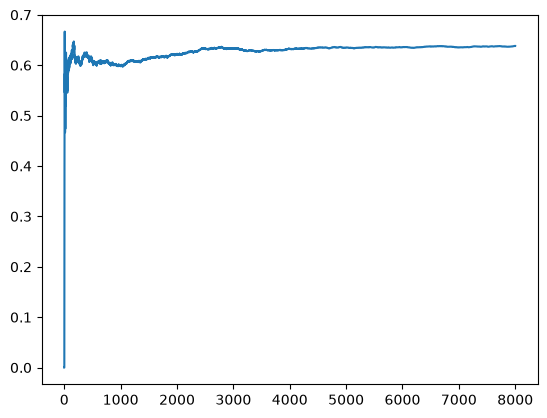

In [6]:
A = aleatorio(8000)
plt.plot(A)
print(A[-1]*np.exp(-0.12*0.25))

In [7]:
print("El valor del call en el presente sera", np.mean(A)*np.exp(-0.12*0.25))


El valor del call en el presente sera 0.6087677389379592
